# Day 16 | Give Each Message a Role

**KGP Talkie**

Separate steady rules, user requests, and earlier replies.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

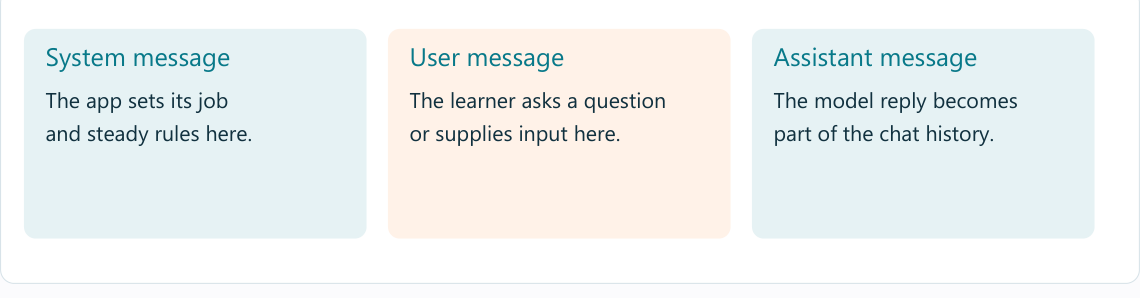

ChatOllama sends chat requests to the local Ollama server.

In [4]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [5]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [6]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

SystemMessage holds the shared rule; HumanMessage holds this turn's question.

In [9]:
from langchain_core.messages import SystemMessage, HumanMessage

In [10]:
question = HumanMessage(content="What is a Python variable?")

In [11]:
beginner = SystemMessage(content="Explain to a beginner. Use two short sentences.")

The list keeps the rule and question as two separate role-labeled messages.

In [12]:
print(llm.invoke([beginner, question]).content)

A Python variable is a name given to a value that can be changed or updated later in the program, allowing you to store and manipulate data. Variables are used to hold values of different types, such as numbers, words, or even other variables, making it easier to work with them throughout your code.


In [11]:
technical = SystemMessage(content="Explain to a programmer. Use one sentence with the programming term.")

Only the system rule changed, so we can compare its effect.

In [12]:
print(llm.invoke([technical, question]).content)

In Python, a variable is a name given to a value that can be changed or updated during the execution of a program.


Now test the same beginner rule with a fresh question.

In [13]:
print(llm.invoke([beginner, HumanMessage(content="What is a Python list?")]).content)

A Python list is a collection of items that can be of any data type, including strings, integers, floats, and other lists. You can think of it like an array or a box where you can store multiple values and perform operations on them.


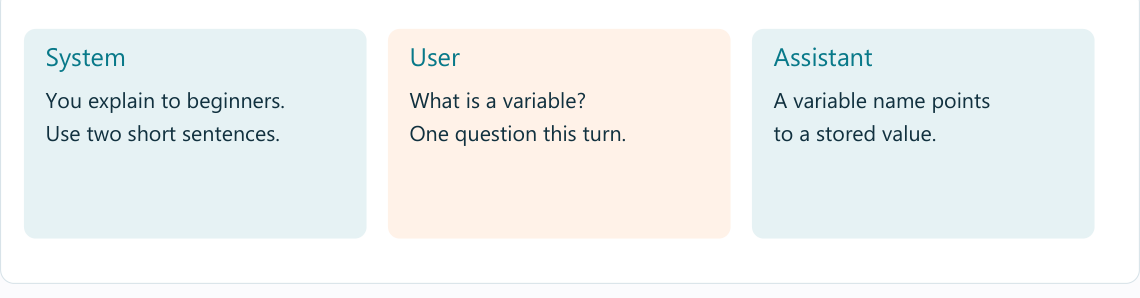

## Try a fresh input

Check what happens when a user asks for a longer answer. A role label is not a guaranteed lock.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/system-prompts-and-roles).